## Use a version 2.x icechunk virtual store to access NASA Earthdata

An example function that can use a virtual icechunk store to access NASA Earthdata either in-cloud or out-of-cloud. The store itself can also be accessed over HTTPS or S3 (the latter only if in-cloud).

Example usage:
```
store_path = (
    "https://archive.podaac.uat.earthdata.nasa.gov/podaac-uat-cumulus-public/
    virtual_collections/SWOT_L2_LR_SSH_Expert_D/
    SWOT_L2_LR_SSH_Expert_D.icechunk_v2.https"
    )
store_auth = ea.login(system=ea.UAT)
chunks_auth = ea.login()
shortname = "SWOT_L2_LR_SSH_Expert_D"
session = open_icechunk_vds(
    store_path, store_auth, 
    chunks_auth, shortname=shortname, chunks_path=None,
    in_cloud_region=False, daac="PODAAC"
)
```

**Potential updates to make**
* When calling ea.search_data() within open_icechunk_vds(), should user creds be made explicit within the function. E.g. should ea.login() be called again, and somehow pass un and pw to it from the chunks_auth input?

In [22]:
import icechunk
import xarray as xr
import earthaccess as ea
import os
from urllib.parse import urlparse

In [38]:
def open_icechunk_vds(store_path, store_auth, 
                      chunks_auth, shortname=None, chunks_path=None,
                      in_cloud_region=False, daac="PODAAC"):
    """
    Open an icechunk virtual data store which can then be passed to packages like Xarray to open the 
    underlying data ("chunks"). Assumes icechunk version 2.x. Only one of either 'shortname' or 'chunks_path'
    should be specified. The former is convenient as the logic in this function will automatically
    find the location in NASA Earthdata of the underlying data chunks.

    Inputs
    ------
    store_path: str
        Path to the icechunk store, either HTTPS or S3.
    store_auth: earthaccess.auth.Auth
        The results from a call to earthaccess.login. E.g. store_auth = earthaccess.login(). Contains
        authentication credentials needed to access the icechunk store on NASA Earthdata.
    chunks_auth: earthaccess.auth.Auth
        The results from a call to earthaccess.login. E.g. store_auth = earthaccess.login(). Contains
        authentication credentials needed to access the data files that the icechunk store points to
        on NASA Earthdata. For most use cases this will be the same instance as 'store_auth'.
    shortname: str
        NASA Earthdata shortname identifier of the dataset.
    chunks_path: str
        (Optional) path to the icechunk store, either HTTPS or S3.
    in_cloud_region: bool
        Set to True when accessing the underlying data chunks via S3 in the same region as the data. 
        Otherwise set to False for HTTPS access.
    daac: str
        Keyword name of DAAC, e.g. "PODAAC".

    Returns
    -------
    icechunk.store.IcechunkStore
        Store instance of the icechunk store. This can be passed to e.g. xarray.open_zarr().
    """
    if shortname==None and chunks_path==None:
        print("One of keywords shortname or chunk_path needs to be specified for function open_icechunk_vds().")
        return

    ## --- Setup storage options for the store ---:
    if store_path.startswith("https://"):
        storage = icechunk.http_storage(store_path)
    
    elif store_path.startswith("s3://"):
        s3creds_store = store_auth.get_s3_credentials(daac=daac)
        bucket, _, prefix = store_path[len("s3://"):].partition("/")
        storage = icechunk.s3_storage(
            bucket=bucket,
            prefix=prefix,
            region="us-west-2",
            access_key_id=s3creds_store['accessKeyId'],
            secret_access_key=s3creds_store['secretAccessKey'],
            session_token=s3creds_store['sessionToken']
        )

    
    ## --- Setup virtual chunk container ---:

    # Chunk bucket/prefix, from earthaccess if not given directly
    if chunks_path==None:
        granule = ea.search_data(short_name=shortname, count=1)[0]
        if in_cloud_region:
            link = urlparse(granule.data_links(access="direct")[0])  # s3://bucket/key
            chunks_path = f"s3://{link.netloc}/"
        else:
            link = urlparse(granule.data_links(access="external")[0])  # https://host/bucket/key
            chunks_path = f"{link.scheme}://{link.netloc}/{link.path.split('/')[1]}/"

    # Declare the virtual chunk container and authorize it with the chunk credentials
    config = icechunk.Repository.fetch_config(storage)

    if in_cloud_region:
        config.set_virtual_chunk_container(icechunk.VirtualChunkContainer(chunks_path, icechunk.s3_store(region="us-west-2")))
        s3creds_chunks = chunks_auth.get_s3_credentials(daac=daac)
        auth_map = icechunk.containers_credentials({
            chunks_path: icechunk.s3_static_credentials(
                access_key_id=s3creds_chunks["accessKeyId"],
                secret_access_key=s3creds_chunks["secretAccessKey"],
                session_token=s3creds_chunks["sessionToken"],
            )
        })
    else:
        https_store = icechunk.http_store(headers={"Authorization": f"Bearer {chunks_auth.token["access_token"]}"})
        config.set_virtual_chunk_container(icechunk.VirtualChunkContainer(chunks_path, https_store))
        auth_map = {chunks_path: icechunk.credentials.HttpAccess}        


    # --- Open Repo and Return Session ---:
    if in_cloud_region:
        repo = icechunk.Repository.open(storage, authorize_virtual_chunk_access=auth_map)
    else:
        repo = icechunk.Repository.open(storage, config=config, authorize_virtual_chunk_access=auth_map)
    return repo.readonly_session("main").store  # Set branch to main.

In [47]:
# store_path = (
#     "https://archive.podaac.uat.earthdata.nasa.gov/podaac-uat-cumulus-public/"
#     "virtual_collections/OSTIA-UKMO-L4-GLOB-REP-v2.0/OSTIA-UKMO-L4-GLOB-REP-v2.0.icechunk_v2.https"
# )
#store_path = "https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-public/virtual_collections/OSTIA-UKMO-L4-GLOB-REP-v2.0/OSTIA-UKMO-L4-GLOB-REP-v2.0.icechunk_v2.s3"
# store_path = "s3://podaac-ops-cumulus-public/virtual_collections/OSTIA-UKMO-L4-GLOB-REP-v2.0/OSTIA-UKMO-L4-GLOB-REP-v2.0.icechunk_v2.s3"
store_path = "https://archive.podaac.uat.earthdata.nasa.gov/podaac-uat-cumulus-public/virtual_collections/SWOT_L2_LR_SSH_Expert_D/SWOT_L2_LR_SSH_Expert_D.icechunk_v2.https"
store_auth = ea.login(system=ea.UAT)
chunks_auth = ea.login()
# shortname = "OSTIA-UKMO-L4-GLOB-REP-v2.0"
shortname = "SWOT_L2_LR_SSH_Expert_D"
session = open_icechunk_vds(
    store_path, store_auth, 
    chunks_auth, shortname=shortname, chunks_path=None,
    in_cloud_region=False, daac="PODAAC"
)

In [48]:
ds = xr.open_zarr(session, consolidated=False)
print(ds)

<xarray.Dataset> Size: 11TB
Dimensions:                                (granule: 27010, num_lines: 9866,
                                            num_pixels: 69, num_sides: 2)
Coordinates:
  * granule                                (granule) int64 216kB 0 1 ... 27009
    filename                               (granule) <U72 8MB ...
    cycle                                  (granule) int64 216kB ...
    orbit                                  (granule) datetime64[ns] 216kB ...
    ppass                                  (granule) int64 216kB ...
    longitude_nadir                        (num_lines) float64 79kB ...
    latitude_nadir                         (num_lines) float64 79kB ...
    latitude                               (granule, num_lines, num_pixels) float64 147GB ...
    longitude                              (granule, num_lines, num_pixels) float64 147GB ...
Dimensions without coordinates: num_lines, num_pixels, num_sides
Data variables: (12/98)
    cross_track_angle     

In [ ]:
#ds.isel(time=0)["analysed_sst"].plot()

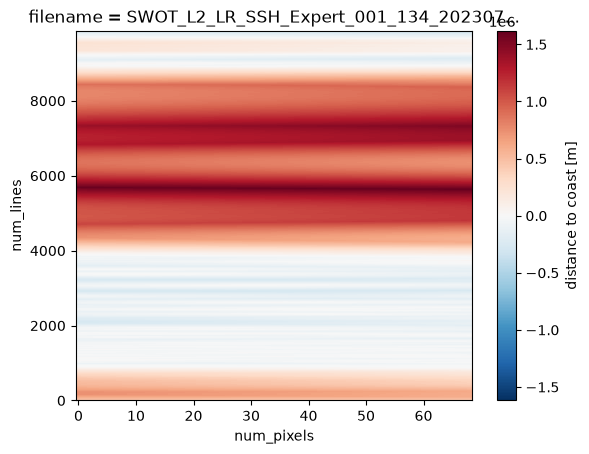

In [49]:
ds.isel(granule=0)["distance_to_coast"].plot()